# Mini-Project 1: UBOS District Population Forecaster
**Scenario.** A district planning unit needs 5-year population forecasts (2025-2029) to plan primary-school classrooms.
Kampala, Wakiso and Gulu come from the brief; **Mbarara and Jinja are illustrative districts I added** (thousands of people, 2015-2024).

In [1]:
import sys; sys.path.insert(0, "..")
import statistics
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.population import *

pd.set_option("display.float_format", "{:,.2f}".format)
SEED = 42
districts = load_districts()

## Task 1: the `DistrictPopulation` class
Validation (equal lengths, no negatives, increasing years) lives in `__init__`; `__repr__` and `__len__` are implemented.

In [2]:
for d in districts.values():
    print(repr(d), "| len =", len(d))

# validation in action
for bad in [([2020, 2021], [1]), ([2020, 2021], [1, -5])]:
    try:
        DistrictPopulation("bad", *bad)
    except ValueError as e:
        print("rejected ->", e)

DistrictPopulation(name='Kampala', years=2015-2024, n=10, last=1800k) | len = 10
DistrictPopulation(name='Wakiso', years=2015-2024, n=10, last=1670k) | len = 10
DistrictPopulation(name='Gulu', years=2015-2024, n=10, last=480k) | len = 10
DistrictPopulation(name='Mbarara', years=2015-2024, n=10, last=655k) | len = 10
DistrictPopulation(name='Jinja', years=2015-2024, n=10, last=494k) | len = 10
rejected -> years (2) and populations (1) must have equal length
rejected -> populations must not be negative


## Task 2: descriptive statistics, `statistics` module vs NumPy
`statistics.variance` / `stdev` use the **sample** formula (divide by *n-1*). `np.var` / `np.std` default to the **population** formula (`ddof=0`, divide by *n*). `ddof` ("delta degrees of freedom") sets the divisor to *n - ddof*, so `ddof=1` reproduces the `statistics` result. With n = 10 the sample variance is 10/9 = 1.11 times larger.

In [3]:
rows = []
for n, d in districts.items():
    s, p0, p1 = d.stats_statistics_module(), d.stats_numpy(0), d.stats_numpy(1)
    rows.append(dict(district=n, mean=s["mean"], median=s["median"],
                     var_statistics=s["variance"], var_np_ddof0=p0["variance"], var_np_ddof1=p1["variance"],
                     std_statistics=s["std"], std_np_ddof0=p0["std"]))
stats_df = pd.DataFrame(rows).set_index("district")
display(stats_df)
assert np.allclose(stats_df.var_statistics, stats_df.var_np_ddof1)   # ddof=1 == statistics.variance
print("Ratio statistics/np (ddof=0):", (stats_df.var_statistics / stats_df.var_np_ddof0).round(4).unique())

,mean,median,var_statistics,var_np_ddof0,var_np_ddof1,std_statistics,std_np_ddof0
district,,,,,,,
Kampala,"1,477.00","1,460.00","42,601.11","38,341.00","42,601.11",206.40,195.81
Wakiso,"1,280.00","1,260.00","60,066.67","54,060.00","60,066.67",245.09,232.51
Gulu,389.50,382.50,"2,885.83","2,597.25","2,885.83",53.72,50.96
Mbarara,561.80,558.00,"3,499.73","3,149.76","3,499.73",59.16,56.12
Jinja,459.10,463.50,796.54,716.89,796.54,28.22,26.77


Ratio statistics/np (ddof=0): [1.1111]


## Task 3: year-on-year growth and CAGR

In [4]:
yoy = pd.DataFrame({n: d.yoy_growth() * 100 for n, d in districts.items()}, index=YEARS[1:])
yoy.index.name = "year"
display(yoy.round(2))
cagr = pd.Series({n: d.cagr() * 100 for n, d in districts.items()}, name="CAGR %").sort_values(ascending=False)
display(cagr.to_frame())
print(f"Fastest relative growth: {cagr.index[0]} ({cagr.iloc[0]:.2f}% a year)")

,Kampala,Wakiso,Gulu,Mbarara,Jinja
year,,,,,
2016,4.17,5.26,3.12,3.12,3.66
2017,4.00,7.00,4.55,3.43,3.06
2018,3.85,7.48,4.35,3.52,2.51
2019,5.19,6.09,4.17,3.40,2.23
2020,5.63,6.56,4.00,3.65,1.96
2021,5.33,6.92,5.13,3.52,1.71
2022,4.43,6.47,4.88,3.74,1.47
2023,4.24,6.08,5.81,3.61,1.24
2024,4.65,6.37,5.49,3.64,1.02


,CAGR %
Wakiso,6.47
Kampala,4.61
Gulu,4.61
Mbarara,3.51
Jinja,2.09


Fastest relative growth: Wakiso (6.47% a year)


## Tasks 4-5: validate before forecasting
Three `Forecaster` subclasses (`LinearTrend`, `ExponentialGrowth`, `FibonacciRatio`) are trained on 2015-2021 and tested on 2022-2024. The best model per district is the one with the lowest **RMSE** (it penalises large misses, which matter for capacity planning).

In [5]:
best = {}
for n, d in districts.items():
    table, best[n] = evaluate_models(d, last_train_year=2021)
    print(f"--- {n}  (best: {best[n]})")
    display(pd.DataFrame(table).T.round(2))

--- Kampala  (best: Exponential (CAGR))


,MAE,RMSE,MAPE
Linear trend,37.62,38.97,2.17
Exponential (CAGR),9.62,10.39,0.55
Fibonacci ratio,14.57,14.95,0.84


--- Wakiso  (best: Exponential (CAGR))


,MAE,RMSE,MAPE
Linear trend,49.40,52.37,3.09
Exponential (CAGR),6.80,8.05,0.42
Fibonacci ratio,12.95,13.52,0.81


--- Gulu  (best: Fibonacci ratio)


,MAE,RMSE,MAPE
Linear trend,18.57,20.29,4.01
Exponential (CAGR),9.44,10.87,2.02
Fibonacci ratio,8.29,9.94,1.77


--- Mbarara  (best: Fibonacci ratio)


,MAE,RMSE,MAPE
Linear trend,10.40,11.02,1.63
Exponential (CAGR),2.94,3.10,0.46
Fibonacci ratio,1.63,1.97,0.25


--- Jinja  (best: Linear trend)


,MAE,RMSE,MAPE
Linear trend,12.23,13.00,2.49
Exponential (CAGR),11.72,13.02,2.39
Fibonacci ratio,12.51,13.72,2.55


## Task 6: forecast 2025-2029 with the selected model (refit on all 10 years)

In [6]:
H = 5
FUT = np.arange(2025, 2030)
forecasts, models = {}, {}
for n, d in districts.items():
    models[n] = model_by_name(best[n]).fit(d.years, d.populations)
    forecasts[n] = models[n].predict(H)

fc_df = pd.DataFrame(forecasts, index=FUT).round(0)
display(fc_df)

# variance: actual series vs forecast series
rows = []
for n, d in districts.items():
    rows.append(dict(district=n,
                     var_actual_10y=statistics.variance(d.populations),
                     var_actual_last5=statistics.variance(d.populations[-5:]),
                     var_forecast_5y=statistics.variance(forecasts[n])))
var_df = pd.DataFrame(rows).set_index("district")
display(var_df)

,Kampala,Wakiso,Gulu,Mbarara,Jinja
2025,"1,883.00","1,778.00",504.00,680.00,510.00
2026,"1,970.00","1,893.00",526.00,703.00,519.00
2027,"2,060.00","2,015.00",551.00,728.00,528.00
2028,"2,155.00","2,146.00",576.00,753.00,537.00
2029,"2,255.00","2,285.00",603.00,780.00,547.00


,var_actual_10y,var_actual_last5,var_forecast_5y
district,,,
Kampala,"42,601.11","13,700.00","21,607.68"
Wakiso,"60,066.67","21,170.00","40,131.36"
Gulu,"2,885.83","1,270.00","1,537.53"
Mbarara,"3,499.73","1,188.80","1,573.68"
Jinja,796.54,106.50,211.88


**Reading the variance table.** The forecast series has *lower* variance than the 10-year actual series. Two reasons: (1) it covers only 5 points, so it spans a shorter stretch of a rising trend, and the variance of a trending series grows with the window length; compare against the last-5-years column for a like-for-like check; (2) a model forecast is a smooth deterministic path with the noise removed, whereas actual data carry irregular year-to-year wiggles. Lower forecast variance therefore does **not** mean the future will be less volatile; it means the model does not forecast shocks.

## Task 7 + Extension: actual, fitted, test predictions and forecast with 95 % bootstrap intervals

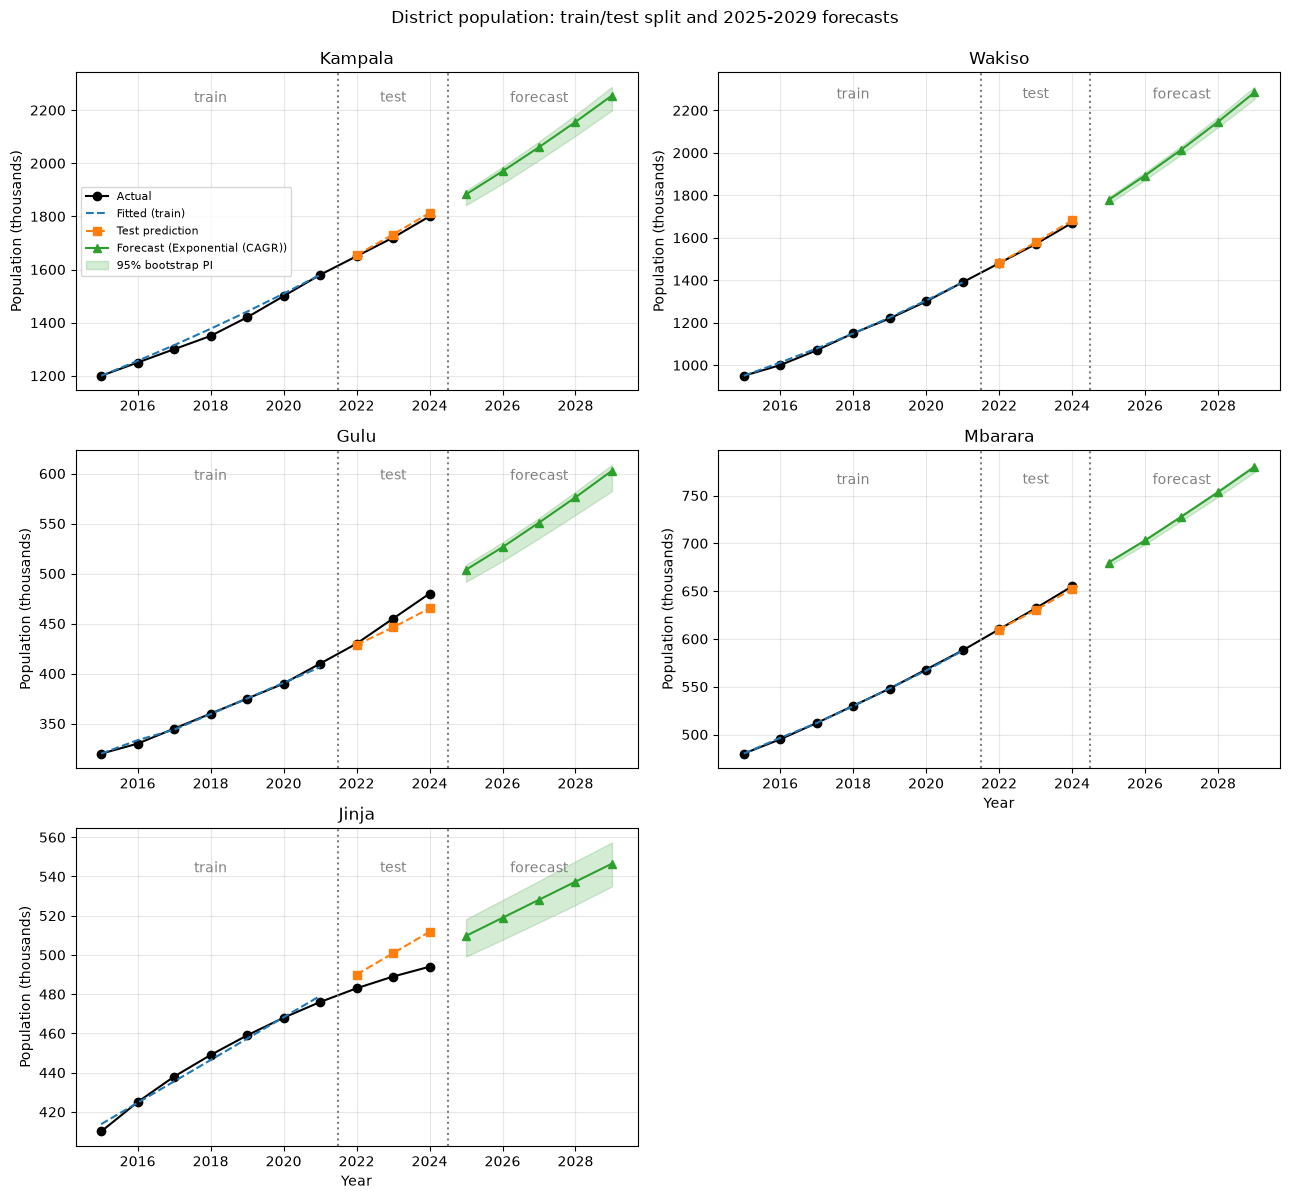

{'Kampala': '89k wide in 2029', 'Wakiso': '58k wide in 2029', 'Gulu': '26k wide in 2029', 'Mbarara': '8k wide in 2029', 'Jinja': '22k wide in 2029'}


In [7]:
fig, axes = plt.subplots(3, 2, figsize=(13, 12), sharex=True)
axes = axes.ravel()
ci = {}
for ax, (n, d) in zip(axes, districts.items()):
    train, test = d.split(2021)
    m_train = model_by_name(best[n]).fit(train.years, train.populations)
    lo, hi = bootstrap_intervals(models[n], H, n_boot=2000, seed=SEED)
    ci[n] = (lo, hi)
    ax.plot(d.years, d.populations, "ko-", label="Actual")
    ax.plot(train.years, m_train.fitted_values(), "--", color="tab:blue", label="Fitted (train)")
    ax.plot(test.years, m_train.predict(len(test)), "s--", color="tab:orange", label="Test prediction")
    ax.plot(FUT, forecasts[n], "^-", color="tab:green", label=f"Forecast ({best[n]})")
    ax.fill_between(FUT, lo, hi, color="tab:green", alpha=0.2, label="95% bootstrap PI")
    ax.axvline(2021.5, color="grey", ls=":"); ax.axvline(2024.5, color="grey", ls=":")
    ax.text(2018, ax.get_ylim()[1] * 0.97, "train", ha="center", va="top", color="grey")
    ax.text(2023, ax.get_ylim()[1] * 0.97, "test", ha="center", va="top", color="grey")
    ax.text(2027, ax.get_ylim()[1] * 0.97, "forecast", ha="center", va="top", color="grey")
    ax.set_title(n); ax.set_ylabel("Population (thousands)"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8, loc="center left")
axes[-1].axis("off")
for ax in axes[:-1]: ax.tick_params(labelbottom=True)
for ax in axes[-3:-1]: ax.set_xlabel("Year")
fig.suptitle("District population: train/test split and 2025-2029 forecasts", y=0.995)
fig.tight_layout()
fig.savefig("../figures/p1_forecasts.png", dpi=150)
plt.show()
print({n: f"{hi[-1]-lo[-1]:.0f}k wide in 2029" for n, (lo, hi) in ci.items()})

## Task 8: classroom planning
18 % of the population is primary-school age; one classroom holds 53 pupils. *Additional* classrooms = need in 2029 minus need in 2024 (both rounded up).

In [8]:
rows = []
for n, d in districts.items():
    now, then = classrooms_needed(d.populations[-1]), classrooms_needed(forecasts[n][-1])
    lo, hi = ci[n]
    rows.append(dict(district=n, pupils_2024=d.populations[-1]*180, classrooms_2024=now,
                     classrooms_2029=then, additional=then-now,
                     additional_low=classrooms_needed(lo[-1])-now, additional_high=classrooms_needed(hi[-1])-now))
class_df = pd.DataFrame(rows).set_index("district")
display(class_df)
print("Total additional classrooms across the 5 districts:", class_df.additional.sum())

,pupils_2024,classrooms_2024,classrooms_2029,additional,additional_low,additional_high
district,,,,,,
Kampala,"324,000.00",6114,7658,1544,1355,1656
Wakiso,"300,600.00",5672,7760,2088,1982,2177
Gulu,"86,400.00",1631,2048,417,348,438
Mbarara,"117,900.00",2225,2650,425,406,433
Jinja,"88,920.00",1678,1857,179,139,215


Total additional classrooms across the 5 districts: 4653


## Extension: critical assessment of the Fibonacci-ratio model

In [9]:
fibs = fibonacci(14)
ratios = [fibs[k] / fibs[k-1] for k in range(1, 14)]
print("Fibonacci ratios F(k+1)/F(k):", np.round(ratios, 3))
print("Golden ratio:", round(PHI, 4))

d = districts["Kampala"]
raw = FibonacciRatio(calibrate=False).fit(d.years, d.populations).predict(H)
cal = FibonacciRatio(calibrate=True).fit(d.years, d.populations).predict(H)
expo = ExponentialGrowth().fit(d.years, d.populations).predict(H)
display(pd.DataFrame({"raw ratios": raw, "calibrated": cal, "exponential (CAGR)": expo}, index=FUT).round(0))

Fibonacci ratios F(k+1)/F(k): [1.    2.    1.5   1.667 1.6   1.625 1.615 1.619 1.618 1.618 1.618 1.618
 1.618]
Golden ratio: 1.618


,raw ratios,calibrated,exponential (CAGR)
2025,"3,000.00","1,890.00","1,883.00"
2026,"4,800.00","1,974.00","1,970.00"
2027,"7,800.00","2,066.00","2,060.00"
2028,"12,600.00","2,161.00","2,155.00"
2029,"20,400.00","2,261.00","2,255.00"


**Assessment.** Raw Fibonacci ratios settle at about 1.618, i.e. roughly **+62 % growth every year**, so Kampala would reach about 20,400k (20 million) by 2029, more than ten times today's figure. That is demographically absurd; Uganda's national growth is roughly 3 % a year. The calibrated version rescales the ratios so the long-run step equals the observed mean growth. But the ratios converge to the golden ratio within a few terms, so after calibration the model is essentially constant-rate (exponential) growth with an early wobble that has no demographic meaning. It is defensible only if (a) growth really is geometric and (b) the rate is estimated from data, in which case it adds nothing over the CAGR model. It looked competitive in validation for Gulu and Mbarara mainly because the arithmetic-mean growth rate it uses is slightly higher than the CAGR, which suits series that were still accelerating.

## Findings & Limitations
**Findings.** Wakiso is growing fastest in relative terms (CAGR 6.5 %), ahead of Kampala and Gulu (both about 4.6 %); my illustrative Jinja is slowest (2.1 %). No single model wins everywhere: exponential growth was best for Kampala and Wakiso (RMSE about 10 and 8 thousand against 39 and 52 for the linear trend, which cannot follow accelerating growth); the calibrated Fibonacci model won for Gulu and Mbarara; the linear trend won for Jinja, whose growth is decelerating. This shows the model must match the growth pattern, and that validating on held-out years beats picking a favourite. Wakiso is forecast to pass Kampala in population by 2029 (about 2,285k against 2,255k) and to need the most new classrooms (about 2,090), then Kampala (about 1,540); in total roughly 4,650 extra classrooms are needed across the five districts. The forecast series has lower variance than the history because it is shorter and smooth, not because the future is calmer.

**Limitations.** Only three test years were used, so the model ranking is fragile (for Jinja the three models differ by under 1 RMSE unit). The data are partly illustrative and the bootstrap intervals are narrow because residuals from smooth series are tiny; they capture fitting noise, not structural change such as migration, policy or conflict, so the true uncertainty is larger. Extrapolating a trend five years ahead assumes the past pattern continues. The classroom estimate assumes a fixed 18 % school-age share, 53 pupils per room, full enrolment and no existing spare capacity.